<a href="https://colab.research.google.com/github/vhvaldiviesor/Programacion-para-analitica-descriptiva-y-predictiva/blob/main/269711_02_semana12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nombre: Victor Hugo Valdivieso Rodriguez**

**Matrícula: 269711**

---

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
PALETA_LOCATION = {"NE": "#1E2761", "MW": "#D98E04", "S": "#4C9F70", "W": "#B23A48"}

df = pd.read_csv("college.csv")
datos = df[["salary", "cost", "location"]].copy()

print(f"Dimensiones: {datos.shape}")
datos.head()

Dimensiones: (85, 3)


,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


In [3]:
# Convertimos location a tipo categórico
datos["location"] = datos["location"].astype("category")
print("Tipos de dato:")
print(datos.dtypes)

print("\nEstadísticas descriptivas de salary y cost:")
display(datos[["salary", "cost"]].describe())

print("\nCantidad de datos por categoría en location:")
print(datos["location"].value_counts())

Tipos de dato:
salary         int64
cost           int64
location    category
dtype: object

Estadísticas descriptivas de salary y cost:


,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000



Cantidad de datos por categoría en location:
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64


In [4]:
# One-hot encoding de location con K-1 categorías (drop_first=True evita la trampa de la variable dummy)
location_dummies = pd.get_dummies(datos["location"], prefix="location", drop_first=True).astype(int)
display(location_dummies.head())

print(f"\nCategoría de referencia (la que no aparece como columna): 'MW'")
print(f"Columnas dummy creadas: {list(location_dummies.columns)}")

,location_NE,location_S,location_W
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0



Categoría de referencia (la que no aparece como columna): 'MW'
Columnas dummy creadas: ['location_NE', 'location_S', 'location_W']


**Nota.** El dataset tiene 85 observaciones y `location` tiene 4 categorías: `NE` (25), `W` (21), `S` (20) y `MW` (19), relativamente balanceadas entre sí. Con K=4 categorías, el one-hot encoding con K-1 genera 3 columnas dummy (`location_NE`, `location_S`, `location_W`); `MW` queda como categoría de referencia (la que pandas omite alfabéticamente al usar `drop_first=True`) y sus efectos quedan absorbidos por el intercepto del modelo.

# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




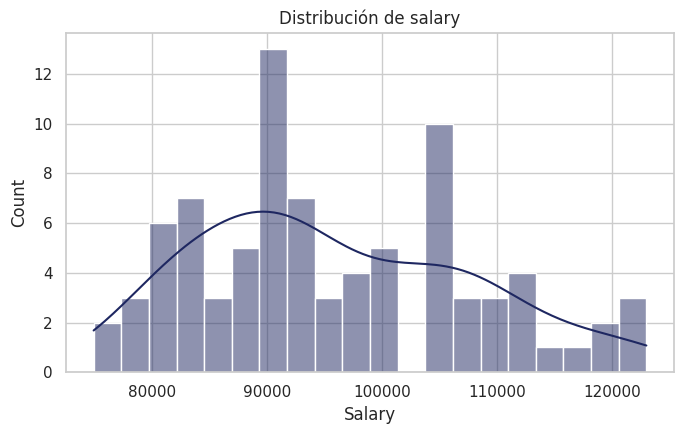

Media: 95898.8, Mediana: 93200.0, Asimetría: 0.439


In [5]:
# Histograma de salary
plt.figure(figsize=(7, 4.5))
sns.histplot(datos["salary"], kde=True, bins=20, color="#1E2761")
plt.xlabel("Salary")
plt.title("Distribución de salary")
plt.tight_layout()
plt.show()

print(f"Media: {datos['salary'].mean():.1f}, Mediana: {datos['salary'].median():.1f}, "
      f"Asimetría: {stats.skew(datos['salary']):.3f}")

**Discusión.** La distribución de `salary` se ve razonablemente acampanada, con media (95,899) y mediana (93,200) cercanas entre sí, y una ligera asimetría positiva (skew = 0.52): hay más universidades con salarios altos "jalando" la cola derecha (hasta 123,000) que casos extremos del lado bajo (el mínimo es 74,900, no tan lejos de la media). No es una distribución perfectamente simétrica, pero tampoco está muy deformada.

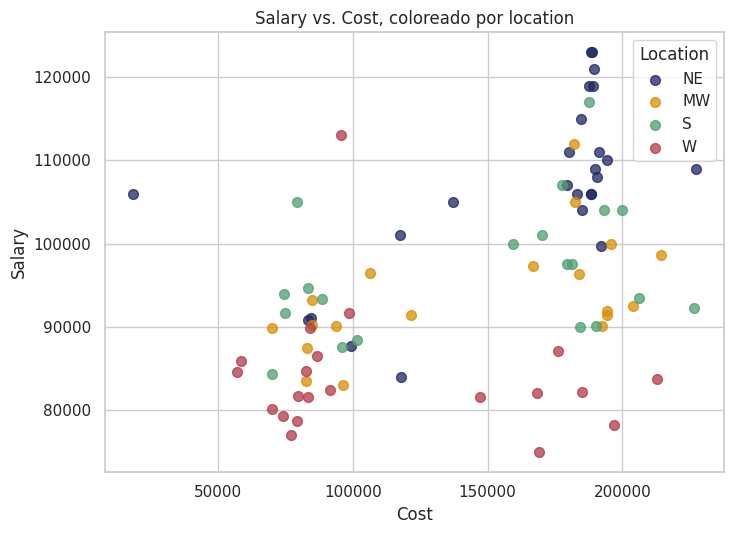

In [6]:
# Dispersión de salary vs cost, coloreado por location
plt.figure(figsize=(7.5, 5.5))
for loc, color in PALETA_LOCATION.items():
    subset = datos[datos["location"] == loc]
    plt.scatter(subset["cost"], subset["salary"], label=loc, color=color, alpha=0.75, s=50)
plt.xlabel("Cost")
plt.ylabel("Salary")
plt.title("Salary vs. Cost, coloreado por location")
plt.legend(title="Location")
plt.tight_layout()
plt.show()

**Discusión.** Se ve una tendencia positiva general: a mayor `cost`, mayor `salary`, pero bastante ruidosa (los puntos no se pegan a una sola línea). Lo más interesante es que los colores no se mezclan al azar: los puntos de `NE` (azul) tienden a estar en la parte alta de `salary` para un `cost` dado, mientras que los de `W` (rojo) tienden a estar más abajo, incluso con `cost` similar a los de `NE` o `S`. Esto sugiere que `location` aporta información sobre `salary` que no está completamente explicada solo por `cost`: dos universidades con el mismo costo pueden tener salarios distintos según la región, lo cual es justo lo que un modelo con variables dummy por `location` intenta capturar.

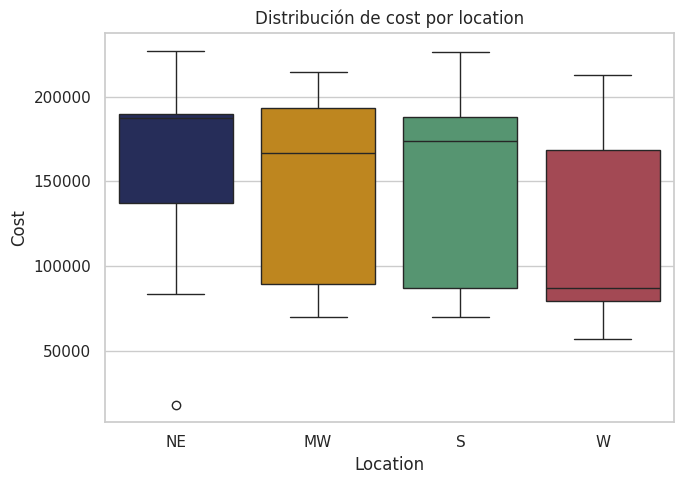

              mean    median      std
location                             
MW        143859.5  166700.0  52897.2
NE        163034.8  187700.0  48754.4
S         146171.5  173950.0  54620.3
W         113061.9   86820.0  50504.0


In [7]:
# Boxplot de cost por location
plt.figure(figsize=(7, 5))
orden_loc = ["NE", "MW", "S", "W"]
sns.boxplot(data=datos, x="location", y="cost", hue="location", order=orden_loc,
            palette=PALETA_LOCATION, legend=False)
plt.xlabel("Location")
plt.ylabel("Cost")
plt.title("Distribución de cost por location")
plt.tight_layout()
plt.show()

print(datos.groupby("location", observed=True)["cost"].agg(["mean", "median", "std"]).round(1))

**Discusión.** Sí hay diferencias claras: `NE` (media 163,035), `S` (146,172) y `MW` (143,859) tienen costos medianos/promedio bastante más altos y similares entre sí, mientras que `W` tiene un costo notablemente más bajo (media 113,062, con una mediana de apenas 86,820, la más baja de las cuatro). Esto es relevante para interpretar el modelo de la parte 3: como `cost` y `location` no son independientes entre sí (el costo típico varía fuerte por región), parte de lo que el coeficiente de `location` "capture" puede estar relacionado con diferencias de costo que no quedaron perfectamente controladas, aunque no se trata de multicolinealidad severa, sino de que ambas variables describen fenómenos regionales relacionados.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [8]:
# Construcción del modelo: salary ~ cost + location (codificada con one-hot, K-1)
X = pd.concat([datos[["cost"]], location_dummies], axis=1)
y = datos["salary"]

modelo = LinearRegression()
modelo.fit(X, y)

print("Intercepto:", modelo.intercept_)
print("Coeficientes:")
for var, coef in zip(X.columns, modelo.coef_):
    print(f"  {var}: {coef:.4f}")

Intercepto: 84988.71622754404
Coeficientes:
  cost: 0.0605
  location_NE: 12032.8197
  location_S: 2800.3450
  location_W: -7721.4201


**Interpretación.**

- **Intercepto (84,988.72):** salario esperado para una universidad de la región `MW` (la categoría de referencia, con todas las dummies en 0) con `cost = 0`. Como en la práctica anterior, es sobre todo un valor técnico que ancla el modelo; ninguna universidad tiene costo 0.
- **`cost` (0.0605):** por cada dólar adicional de costo de la educación, el salario esperado aumenta 0.0605 dólares, manteniendo fija la región (`location`). Dicho de otra forma, 1,000 dólares más de costo se asocian, en promedio, con unos 60.5 dólares más de salario.
- **`location_NE` (+12,032.82):** una universidad en `NE` tiene, en promedio, un salario esperado 12,032.82 dólares **más alto** que una universidad de `MW` con el mismo `cost`.
- **`location_S` (+2,800.35):** una universidad en `S` tiene, en promedio, un salario esperado 2,800.35 dólares más alto que una de `MW` con el mismo `cost` (una diferencia pequeña frente a las otras).
- **`location_W` (-7,721.42):** una universidad en `W` tiene, en promedio, un salario esperado 7,721.42 dólares **más bajo** que una de `MW` con el mismo `cost`.

Para sustituir valores: el salario esperado de una universidad de `NE` con `cost = 150,000` sería 84,988.72 + 0.0605×150,000 + 12,032.82×1 = 84,988.72 + 9,075 + 12,032.82 ≈ **106,096.5**. El mismo cálculo para una universidad `MW` con el mismo costo (todas las dummies en 0) daría 84,988.72 + 9,075 ≈ **94,063.7**, es decir, 12,032.82 menos, exactamente el coeficiente de `location_NE`.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

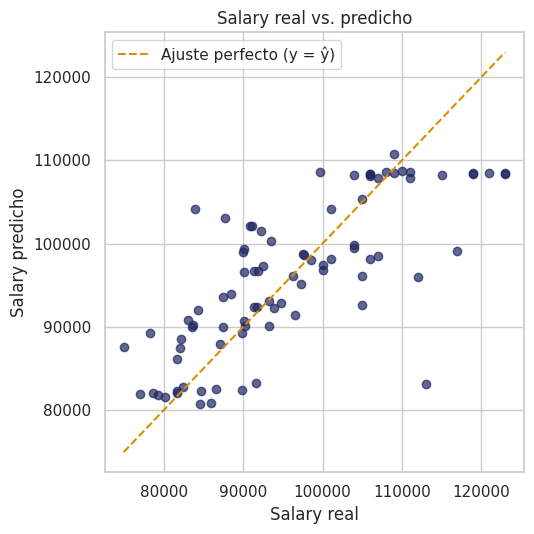

In [9]:
y_pred = modelo.predict(X)
residuos = y - y_pred

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y, y_pred, alpha=0.7, color="#1E2761")
lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
plt.plot(lims, lims, color="#D98E04", linestyle="--", label="Ajuste perfecto (y = ŷ)")
plt.xlabel("Salary real")
plt.ylabel("Salary predicho")
plt.title("Salary real vs. predicho")
plt.legend()
plt.tight_layout()
plt.show()

**Discusión.** Los puntos siguen la dirección general de la línea de ajuste perfecto, pero con bastante dispersión alrededor de ella (consistente con un R² moderado, que se calculará en la parte 5): el modelo capta la tendencia general, pero no predice con precisión el salario exacto de cada universidad. No se ve un sesgo sistemático obvio hacia sobreestimar o subestimar en algún extremo del rango de salarios.

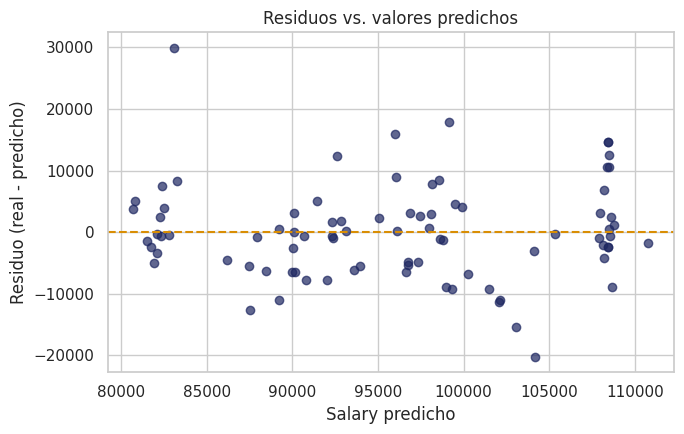

Media de los residuos: 0.0000
Desviación estándar de los residuos: 7823.06
Asimetría (skew): 0.704


In [10]:
plt.figure(figsize=(7, 4.5))
plt.scatter(y_pred, residuos, alpha=0.7, color="#1E2761")
plt.axhline(0, color="#D98E04", linestyle="--")
plt.xlabel("Salary predicho")
plt.ylabel("Residuo (real - predicho)")
plt.title("Residuos vs. valores predichos")
plt.tight_layout()
plt.show()

print(f"Media de los residuos: {residuos.mean():.4f}")
print(f"Desviación estándar de los residuos: {residuos.std():.2f}")
print(f"Asimetría (skew): {stats.skew(residuos):.3f}")

**Discusión.** Los residuos se dispersan alrededor de 0 sin un patrón de embudo evidente, pero tienen asimetría positiva (skew = 0.70): hay algunos residuos positivos grandes (universidades con salario real bastante más alto de lo que predice el modelo) que no tienen un equivalente igual de extremo del lado negativo. Esto sugiere que el modelo subestima el salario en un grupo específico de universidades (probablemente algunas de `NE` con salarios particularmente altos), más que un problema generalizado de varianza no constante.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [11]:
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MSE:  60,480,269.15
RMSE: 7,776.91
R²:   0.5705


**Discusión.** El modelo explica el 57.1% de la variabilidad de `salary` (R² = 0.5705): una mejora real frente a no usar ningún predictor, pero bastante más modesto que el ajuste de la práctica de regresión múltiple de `Sales` (ahí el R² rondaba 0.90). El RMSE de 7,776.91 significa que, en promedio, las predicciones del modelo se desvían del salario real en casi 7,777 dólares, un error considerable frente al rango de `salary` en los datos (de 74,900 a 123,000, con desviación estándar de 11,937). En conjunto, el modelo capta una parte real de la relación entre costo, ubicación y salario, pero deja sin explicar una porción importante (cerca del 43%) de la variación, probablemente por factores no incluidos (prestigio de la universidad, área de estudio, tamaño, etc.).

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

**Nota.** El ejemplo de `variance_components` de statsmodels está pensado para modelos mixtos con efectos aleatorios, que están fuera del alcance de esta práctica (no hay mediciones repetidas ni agrupaciones jerárquicas en `college.csv`). Lo que sí aplica directamente aquí es el uso de la **tabla de análisis de varianza (ANOVA)** de statsmodels para descomponer cuánta variabilidad de `salary` explica cada término del modelo (`cost` y `location`) y si esa contribución es estadísticamente significativa, usando `statsmodels.formula.api` y `anova_lm`.

In [12]:
# Modelo con fórmula (statsmodels detecta y codifica location automáticamente con C(.))
modelo_formula = smf.ols("salary ~ cost + C(location)", data=datos).fit()
print(modelo_formula.summary())

print("\nTabla de análisis de varianza (ANOVA, suma de cuadrados tipo II):")
tabla_anova = sm.stats.anova_lm(modelo_formula, typ=2)
print(tabla_anova)

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           4.96e-14
Time:                        07:57:21   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          8.499e+04   3092.65

**Discusión.** La tabla de ANOVA (tipo II) descompone la suma de cuadrados explicada por cada término:

| Término | Suma de cuadrados | gl | F | p-value |
| --- | --- | --- | --- | --- |
| `C(location)` | 4,071,774,000 | 3 | 21.12 | 3.57 × 10⁻¹⁰ |
| `cost` | 787,816,600 | 1 | 12.26 | 7.60 × 10⁻⁴ |
| Residual | 5,140,823,000 | 80 | — | — |

Ambos términos son altamente significativos (p « 0.05): tanto `location` como `cost` contribuyen de forma estadísticamente significativa a explicar `salary`, incluso controlando uno por el otro. `location` por sí sola explica más suma de cuadrados que `cost` (4,072 millones vs. 788 millones), lo cual es consistente con lo visto en la parte 3: la diferencia entre la región `NE` y la región `W` (casi 20,000 dólares de diferencia en sus coeficientes) es más grande, en términos de variabilidad explicada, que el efecto marginal del costo. Esto confirma, con una prueba formal, lo que ya sugería el diagrama de dispersión de la parte 2: la ubicación de la universidad no es un detalle menor, es una fuente de variación en `salary` tan o más importante que el propio costo de la educación.